In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance
import xgboost as xgb 
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor

In [2]:
df_EPA = pd.read_csv('/Users/siobhankassem/Desktop/USC/Classes/Fall 2026/Python Data Science/Datasets/LA_AQS_2023.csv') 

In [3]:
O3 = df_EPA[(df_EPA['Parameter Name'] == 'Ozone') & (df_EPA['Duration Description']=='1 HOUR')]
NO2 = df_EPA[(df_EPA['Parameter Name'] == 'Nitrogen dioxide (NO2)') & (df_EPA['Duration Description']=='1 HOUR')]
PM = df_EPA[(df_EPA['Parameter Name'] == 'PM2.5 - Local Conditions') & (df_EPA['Duration Description']=='1 HOUR')]

O3_conc = pd.DataFrame(data = {"O3" : O3['Arithmetic Mean'], 'date' : O3['Date (Local)']})
NO2_conc = pd.DataFrame(data = {"NO2" : NO2['Arithmetic Mean'], 'date' : NO2['Date (Local)']})
PM_conc = pd.DataFrame(data = {"PM" : PM['Arithmetic Mean'], 'date' : PM['Date (Local)']})

conc_all = O3_conc.merge(NO2_conc,  on=['date'])
conc_all = conc_all.merge(PM_conc, on='date')
conc_all = conc_all.drop_duplicates()
conc_all["O3"]=conc_all["O3"]*1000

In [4]:
conc_all = conc_all.drop(columns="date")

In [5]:
xVal = conc_all[["O3", "PM"]]
yVal = np.array(conc_all['NO2'])

In [6]:
reg = linear_model.LinearRegression() # this creates a regression object. creates the space for a linear model to be put into. 
reg.fit(xVal,yVal) # in the .fit method that does the optimization (via OSL), using the arrays we just made of x and y

print("Coefficients: \n", reg.coef_)
print("Intercept: \n", reg.intercept_)

Coefficients: 
 [-0.59706218  0.38930036]
Intercept: 
 25.306573877461176


In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(xVal, yVal, test_size=0.20) # xVal and yVal are our x and y values

In [8]:
reg = linear_model.LinearRegression() # need to make a new fit. 
reg.fit(X_train,y_train)
reg.score(X_test, y_test)

0.5059670859229739

In [9]:
xVal

,O3,PM
0,31.708,5.087500
1,31.708,5.087500
4,15.792,9.187500
5,15.792,9.187500
8,25.000,4.312500
...,...,...
1074,35.056,13.883333
1076,39.048,10.875000
1078,39.048,10.875000
1080,30.042,6.416667


In [10]:
metric = 'neg_root_mean_squared_error' #sklearn-specific way of saying RMSE
r = permutation_importance(reg, X_test, y_test,
                           n_repeats=30,
                           scoring=metric,
                           random_state=42)

features = xVal.columns
sorted_imp_idx = r.importances_mean.argsort()


for i in r.importances_mean.argsort()[::-1]:
    print(f"{features[i]:<18} "
            f"{r.importances_mean[i]:.3f}"
            f" +/- {r.importances_std[i]:.3f}")

O3                 3.427 +/- 0.362
PM                 0.840 +/- 0.157


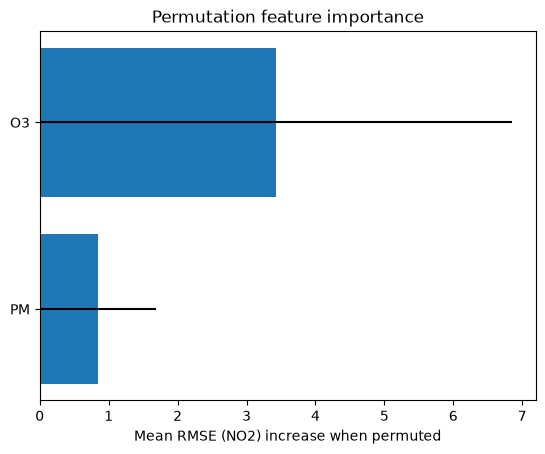

In [11]:
plt.barh(range(len(r.importances_mean)),
         r.importances_mean[sorted_imp_idx],
         xerr = r.importances_mean[sorted_imp_idx]
         )
plt.yticks(range(len(r.importances_mean)), features[sorted_imp_idx])
plt.title('Permutation feature importance')
plt.xlabel('Mean RMSE (NO2) increase when permuted')
plt.show()

In [12]:
# NOAA Buoy

In [13]:
path = '/Users/siobhankassem/Desktop/USC/Classes/Fall 2026/Python Data Science/Datasets/Waves_2023.txt'
waves = pd.read_csv(path, sep=r"\s+")
waves= waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE'], axis=1)
waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]
wavesML = waves.drop(['YY','MM','DD','hh','mm'],axis = 1)


xVal2 = wavesML.drop(['WVHT'], axis=1)

In [14]:
xVal2

,DPD,APD,MWD,WTMP
0,12.50,7.69,269,15.3
1,11.76,7.34,272,15.3
2,12.50,7.08,268,15.3
3,10.53,7.33,268,15.4
4,10.53,7.57,268,15.5
...,...,...,...,...
17280,14.29,11.19,270,16.7
17281,15.38,10.37,267,16.7
17282,13.33,10.50,268,16.8
17283,14.29,10.32,271,16.8


In [15]:
df_X = wavesML.drop(['WVHT'],axis=1).to_numpy() # dropping our target
df_y = wavesML['WVHT'].to_numpy() # what we ar predicting, what we removed from above

X_train2, X_test2, y_train2, y_test2 = train_test_split(df_X, df_y, test_size=0.10) # making training and test data
X_train2, X_val2, y_train2, y_val2 = train_test_split(X_train2, y_train2, test_size=0.10) # taking 10% of the training data and setting it aside for validation data

In [16]:
# XGBR Regressor

XGBR = XGBRegressor(n_estimators=25)
XGBR = XGBR.fit(X_train2, y_train2)

In [17]:
metric = 'neg_root_mean_squared_error' #sklearn-specific way of saying RMSE
r = permutation_importance(XGBR, X_test2, y_test2,
                           n_repeats=30,
                           scoring=metric,
                           random_state=42)

features = xVal2.columns
sorted_imp_idx = r.importances_mean.argsort()


for i in r.importances_mean.argsort()[::-1]:
    print(f"{features[i]:<18} "
            f"{r.importances_mean[i]:.3f}"
            f" +/- {r.importances_std[i]:.3f}")

APD                0.188 +/- 0.009
MWD                0.159 +/- 0.008
WTMP               0.133 +/- 0.008
DPD                0.131 +/- 0.006


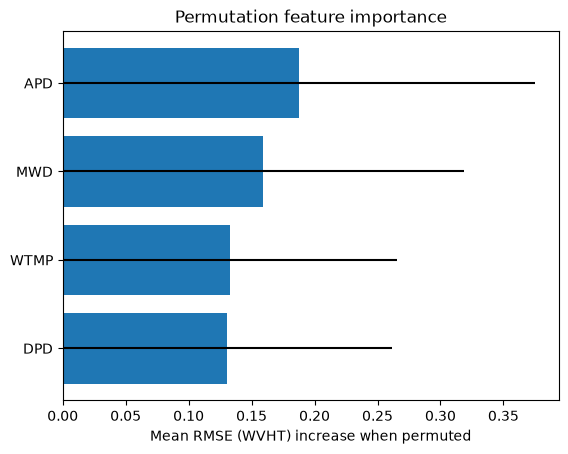

In [18]:
plt.barh(range(len(r.importances_mean)),
         r.importances_mean[sorted_imp_idx],
         xerr = r.importances_mean[sorted_imp_idx]
         )
plt.yticks(range(len(r.importances_mean)), features[sorted_imp_idx])
plt.title('Permutation feature importance')
plt.xlabel('Mean RMSE (WVHT) increase when permuted')
plt.show()

In [19]:
# Linear Regression

baseline_model = LinearRegression()
baseline_model.fit(X_train2, y_train2)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-0.02, 0.12, 0. ,-0.04]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.745
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[5474.18, 413.36, 275.03, 170.19]"


In [20]:
metric = 'neg_root_mean_squared_error' #sklearn-specific way of saying RMSE
r = permutation_importance(baseline_model, X_test2, y_test2,
                           n_repeats=30,
                           scoring=metric,
                           random_state=42)

features = xVal2.columns
sorted_imp_idx = r.importances_mean.argsort()


for i in r.importances_mean.argsort()[::-1]:
    print(f"{features[i]:<18} "
            f"{r.importances_mean[i]:.3f}"
            f" +/- {r.importances_std[i]:.3f}")

APD                0.103 +/- 0.005
WTMP               0.017 +/- 0.002
MWD                0.015 +/- 0.001
DPD                0.011 +/- 0.002


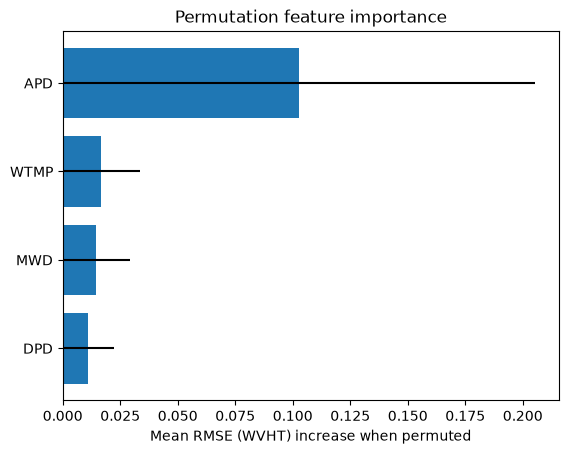

In [21]:
plt.barh(range(len(r.importances_mean)),
         r.importances_mean[sorted_imp_idx],
         xerr = r.importances_mean[sorted_imp_idx]
         )
plt.yticks(range(len(r.importances_mean)), features[sorted_imp_idx])
plt.title('Permutation feature importance')
plt.xlabel('Mean RMSE (WVHT) increase when permuted')
plt.show()

In [22]:
# decision tree

regRF = RandomForestRegressor(n_estimators=100)
regRF = RandomForestRegressor(n_estimators=100)
regRF = regRF.fit(X_train2, y_train2)

In [23]:
metric = 'neg_root_mean_squared_error' #sklearn-specific way of saying RMSE
r = permutation_importance(regRF, X_test2, y_test2,
                           n_repeats=30,
                           scoring=metric,
                           random_state=42)

features = xVal2.columns
sorted_imp_idx = r.importances_mean.argsort()


for i in r.importances_mean.argsort()[::-1]:
    print(f"{features[i]:<18} "
            f"{r.importances_mean[i]:.3f}"
            f" +/- {r.importances_std[i]:.3f}")

APD                0.255 +/- 0.011
MWD                0.223 +/- 0.010
DPD                0.183 +/- 0.009
WTMP               0.166 +/- 0.008


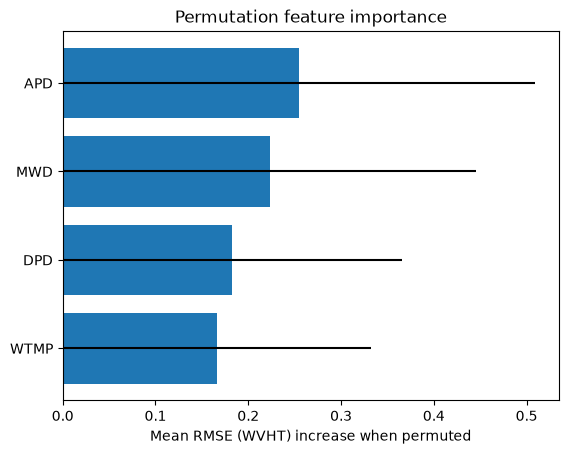

In [24]:
plt.barh(range(len(r.importances_mean)),
         r.importances_mean[sorted_imp_idx],
         xerr = r.importances_mean[sorted_imp_idx]
         )
plt.yticks(range(len(r.importances_mean)), features[sorted_imp_idx])
plt.title('Permutation feature importance')
plt.xlabel('Mean RMSE (WVHT) increase when permuted')
plt.show()

The feature importances are different in the XGB, linear model, and decision tree. In the XGB, the MWD is the most important but in the linear model and decision tree the APD is more important. 

## Paper answers


1. How do they describe the permutation feature importance method we learned
in class?

This paper mentions how feature importance has to do with the quality of the model. It depends on if it is model specific or model agnostic as we talked about in class. Model specific feature importance has to do with how much the set of features contributes to how good the model performs. The model agnostic feature importance has to do with a hypothetical range of contributions of features to a model. This second explanation is worded more confusing in the paper, but i think this method is better because it can be used with any model type. 


2. Describe an additional method for explainability from this paper. How does it
work? Is it model agnostic or model specific?

Tree interpreter is an explainability method and it gives feature attributions based on the path of a decision tree. It explains the models observation of each predicted value rather than grouping all observations together and making a general claim about the model. This is a model specific technique because it only works on trees. 

3. Find potential scikitlearn functions for 5 of the methods described in the paper.
Note: You don’t have to implement them

from treeinterpreter import treeinterpreter as ti
from sagemaker.sklearn.estimator import SKLearn
from lime import lime_tabular
import shap
from sklearn.inspection import PartialDependenceDisplay
from sklearn.inspection import partial_dependence